In [1]:
# Exploratory Data Analysis (EDA) - Company A Telecom
# This cells performs a systematic EDA on the Client and Record datasets

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 200)

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

def find_by_stem(folder: Path, stem: str) -> Path:
    """Find a file by its stem (name without extension) in a given folder."""
    matches = [p for p in folder.iterdir() if p.is_file() and p.stem.lower() == stem.lower()]
    if len(matches) != 1:
        raise FileNotFoundError(f"Found {len(matches)} files with stem {stem!r}: {matches}")
    return matches[0]

def load_table(path: Path) -> pd.DataFrame:
    """Load a table safely, trying CSV then Excel if extension is missing."""
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(path)
    try:
        return pd.read_csv(path)
    except Exception:
        return pd.read_excel(path)

In [2]:
# 1. Load and Merge Datasets
folder = Path(r"C:\FILE PROYEKAN\GCI World 2026\Final Assignment\telecom")

# Load datasets
client_file = find_by_stem(folder, "Client")
record_file = find_by_stem(folder, "Record")

client = load_table(client_file)
record = load_table(record_file)

print(f"Client Shape: {client.shape}")
print(f"Record Shape: {record.shape}")

# Validate Keys
print("\n--- Key Validation ---")
print(f"Client Customer_ID unique: {client['Customer_ID'].is_unique}")
print(f"Record Customer_ID unique: {record['Customer_ID'].is_unique}")

# Merge
df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print(f"\nMerged Shape: {df.shape}")

Client Shape: (100000, 50)
Record Shape: (100000, 51)

--- Key Validation ---
Client Customer_ID unique: True
Record Customer_ID unique: True

Merged Shape: (100000, 100)


Interpretation: Both tables have a unique Customer_ID (1:1 cardinality). The merge process results in a single table with 100,000 rows. No customer data is lost as a result of the join process.

Business Implication: The data is ready for holistic analysis. We can directly link customer profiles (demographics, devices) with their usage behavior and billing.

Top 15 columns with missing values:

                  Missing Count  Missing %
numbcars                  49366     49.366
dwllsize                  38308     38.308
HHstatin                  37923     37.923
ownrent                   33706     33.706
dwlltype                  31909     31.909
lor                       30190     30.190
income                    25436     25.436
adults                    23019     23.019
infobase                  22079     22.079
hnd_webcap                10189     10.189
prizm_social_one           7388      7.388
avg6qty                    2839      2.839
avg6rev                    2839      2.839
avg6mou                    2839      2.839
kid3_5                     1732      1.732


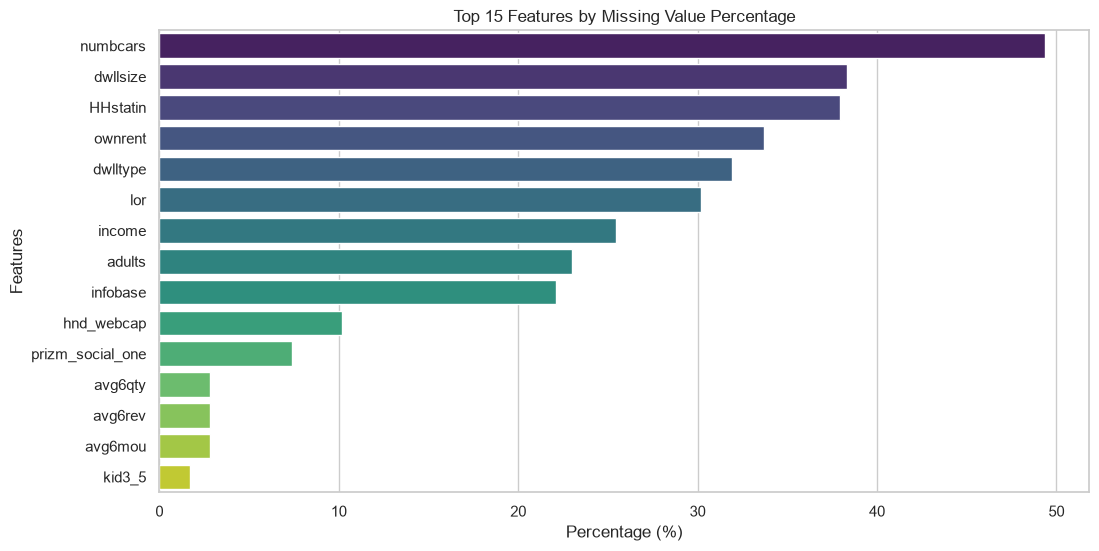


Duplicate rows in merged dataset: 0

Data Type Distribution:
float64    69
str        21
int64      10
Name: count, dtype: int64


In [3]:
# 2. Data Quality Overview
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print("Top 15 columns with missing values:\n")
print(missing_df.head(15))

# Plot Missing Values
plt.figure(figsize=(12, 6))
sns.barplot(x=missing_pct.head(15).values, y=missing_pct.head(15).index, palette="viridis")
plt.title("Top 15 Features by Missing Value Percentage")
plt.xlabel("Percentage (%)")
plt.ylabel("Features")
plt.show()

# Duplicates
print(f"\nDuplicate rows in merged dataset: {df.duplicated().sum()}")

# Data Types
print("\nData Type Distribution:")
print(df.dtypes.value_counts())

**Interpretation (Based on findings from previous testing):** Columns such as `numbcars`, `dwllsize`, and `HHstatin` have very high missing values (>30%). The `change_mou` and `change_rev` columns have very minimal missing values. There are no duplicate rows. There are 21 object-type (string) columns, most of which are demographic data.

**Business Implication:** Columns with extreme missing values may be unreliable for predictive models without advanced imputation or special handling (e.g., categorizing them as "Unknown"). String columns must be encoded before being fed into an ML model.

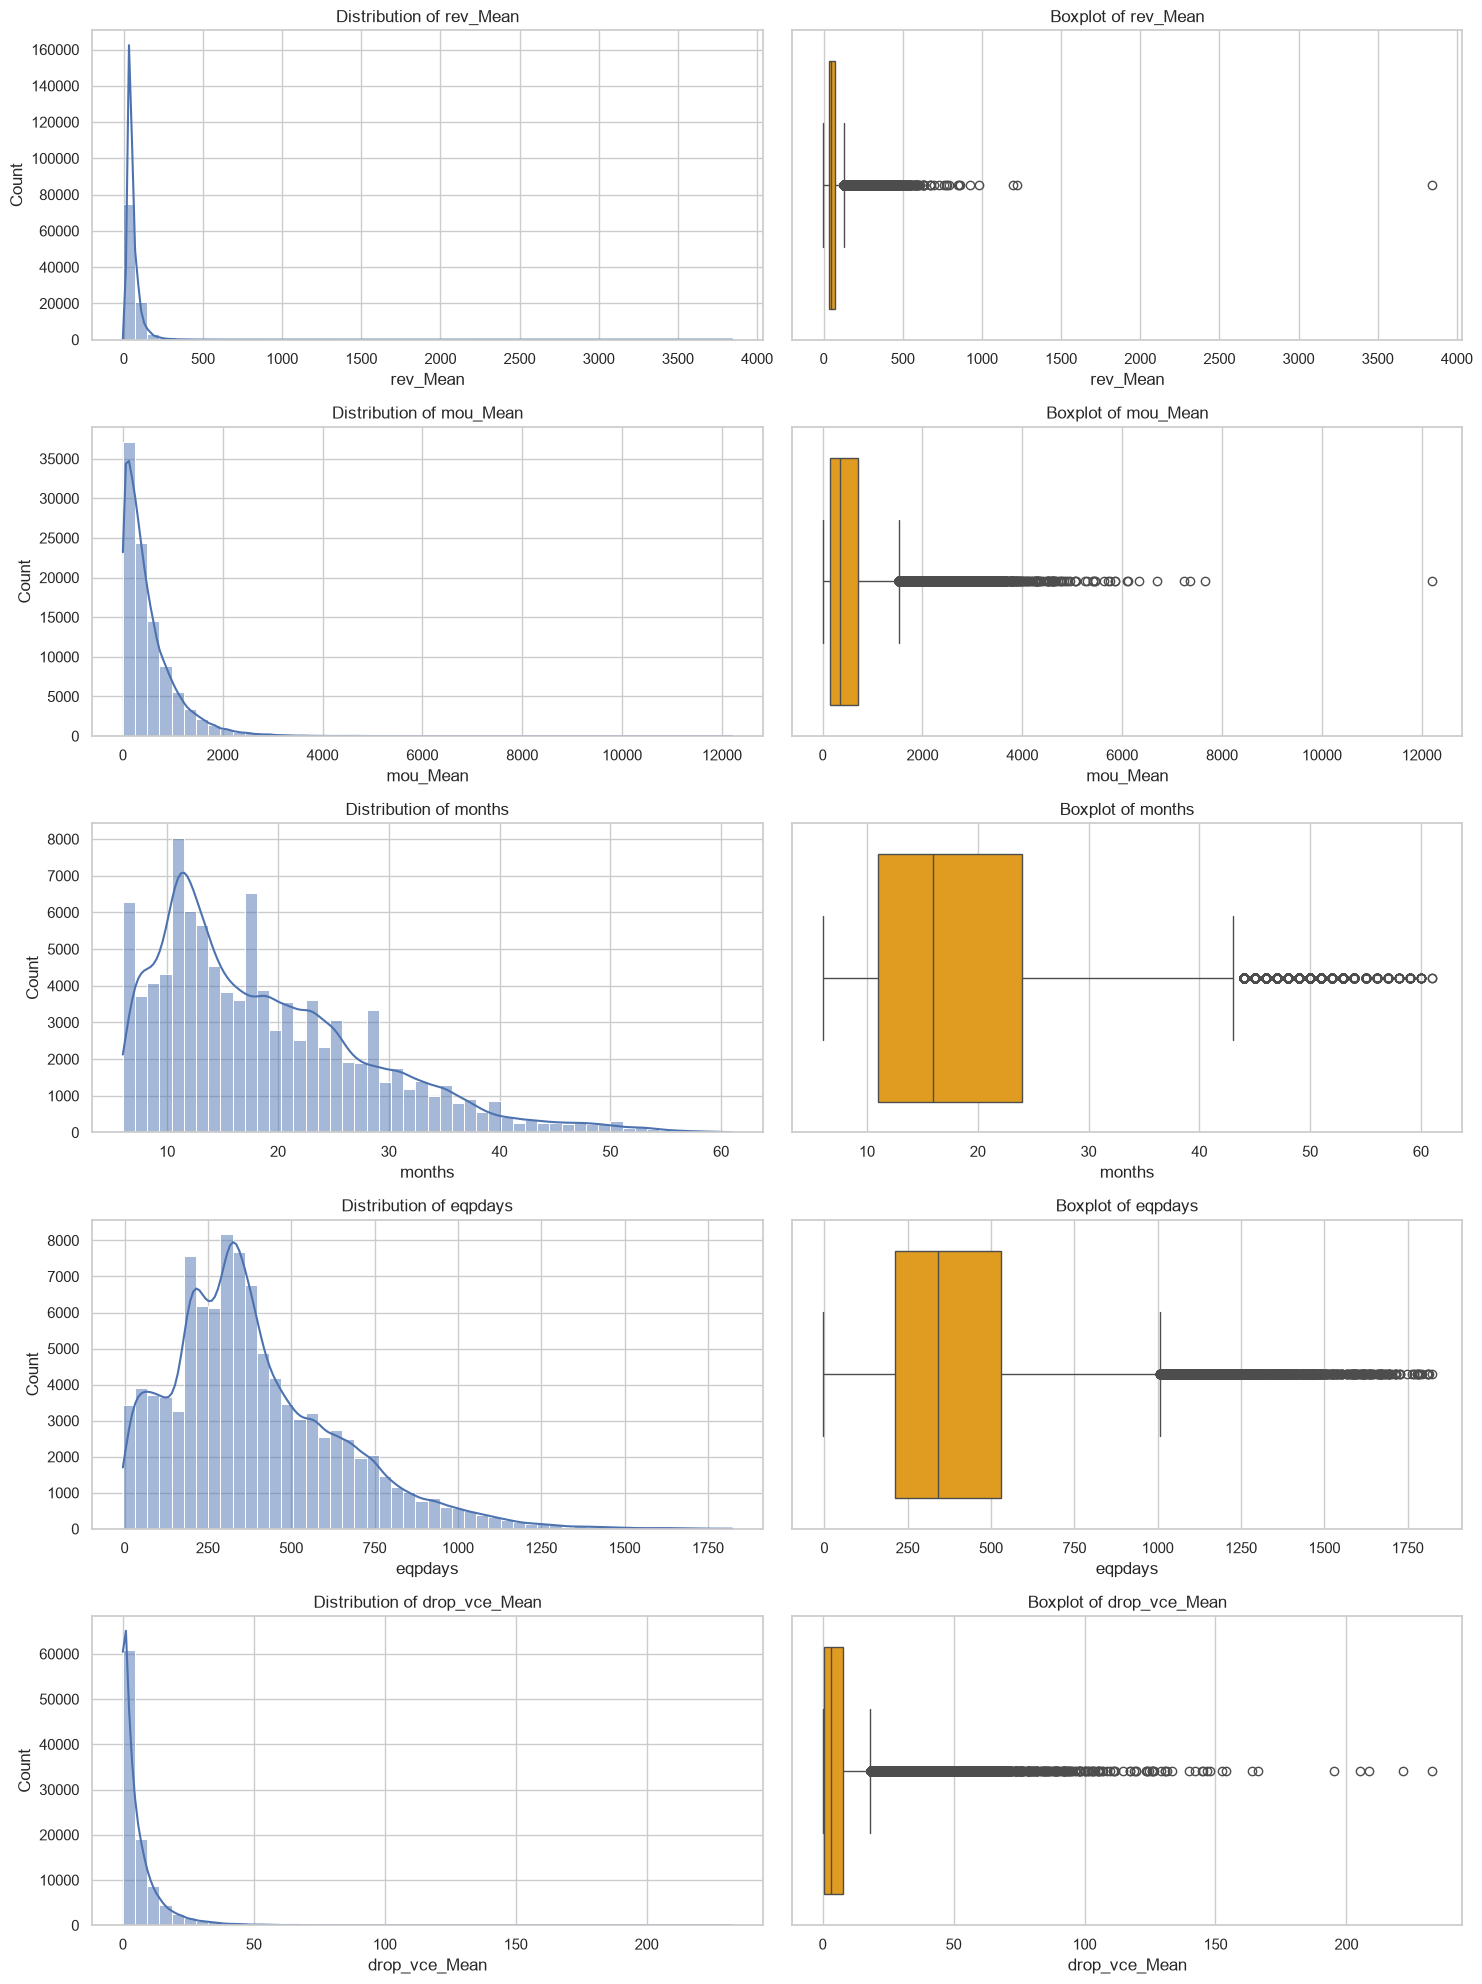

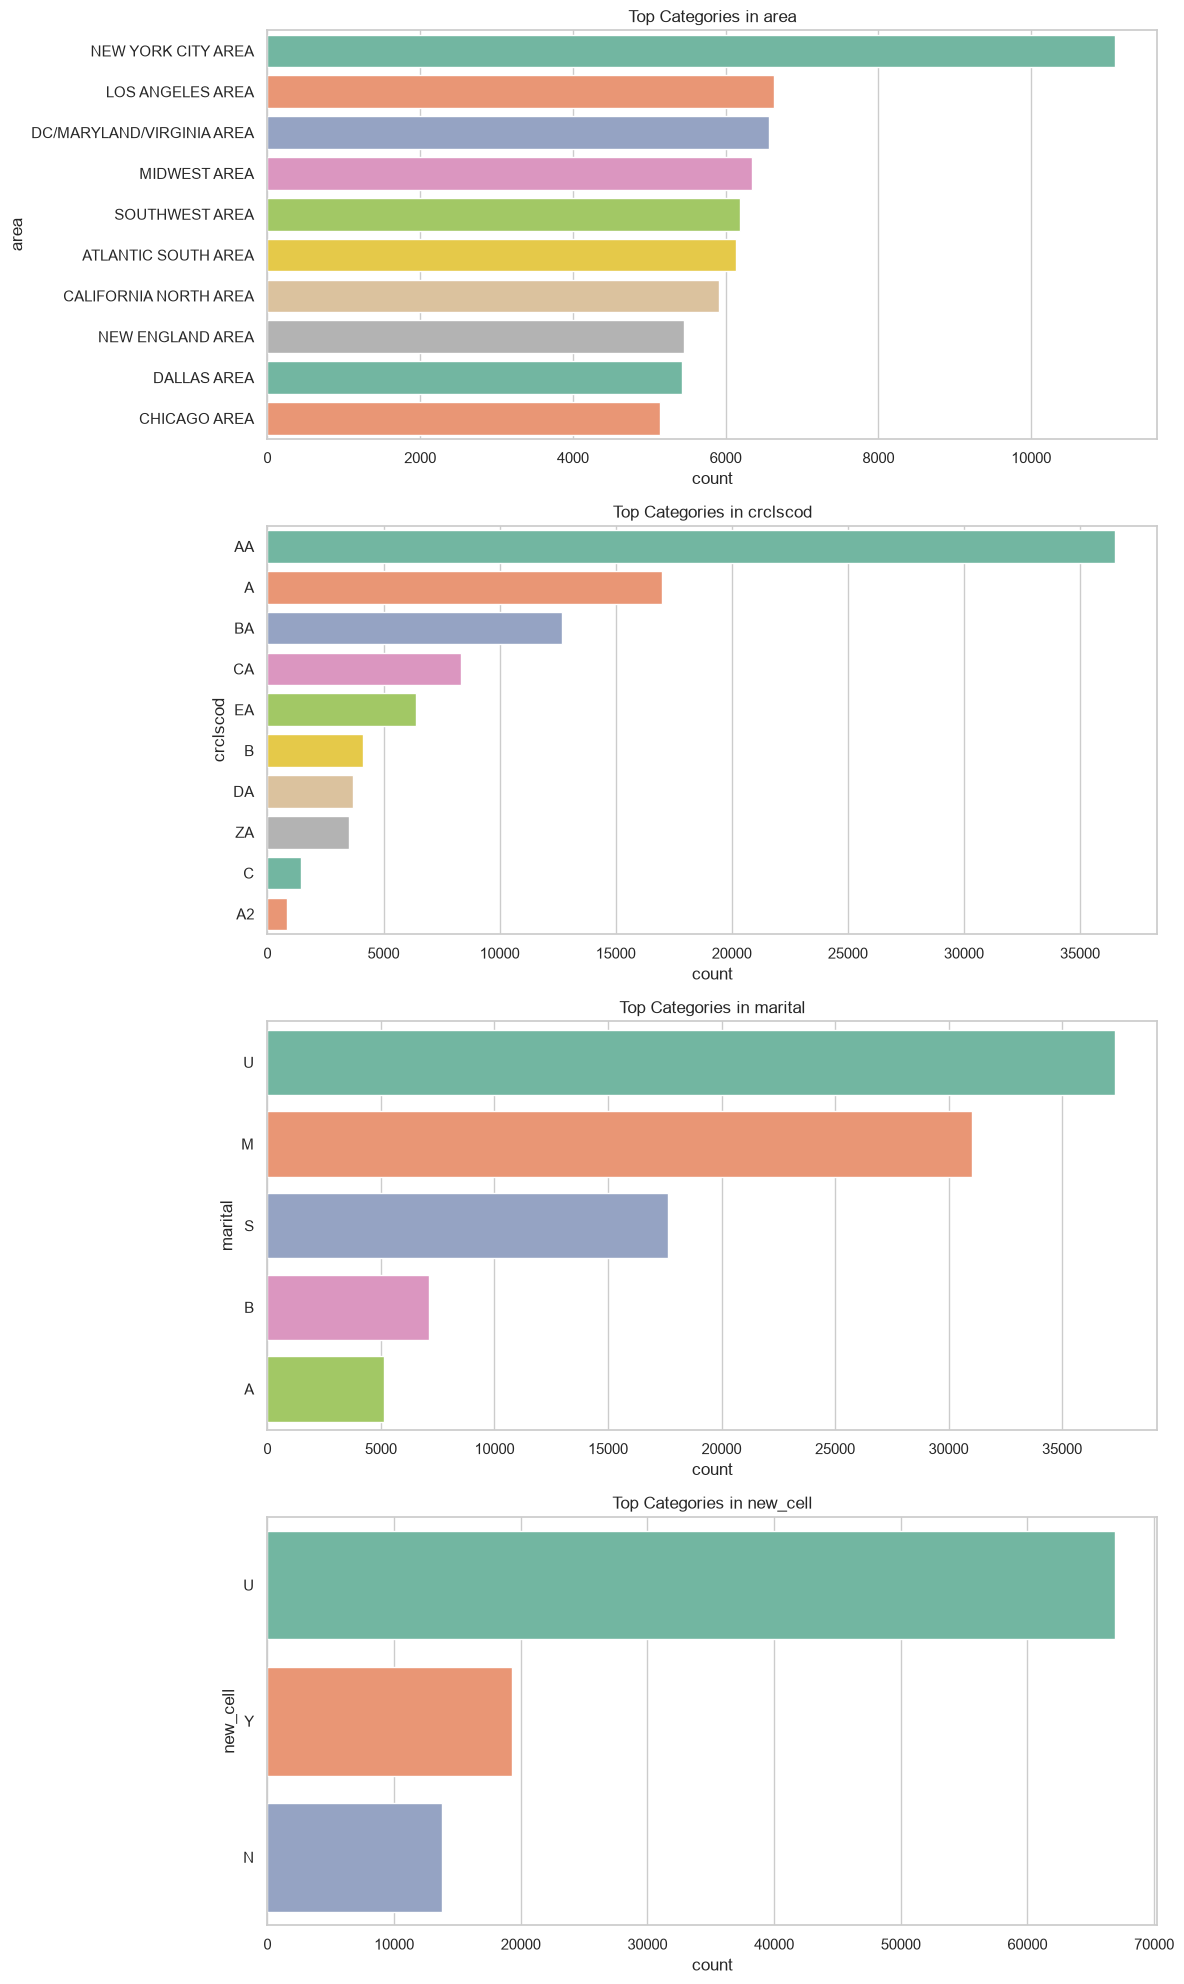

In [4]:
# 3. Univariate Analysis
# Numerical Distributions
num_cols = ['rev_Mean', 'mou_Mean', 'months', 'eqpdays', 'drop_vce_Mean']

fig, axes = plt.subplots(len(num_cols), 2, figsize=(15, 4 * len(num_cols)))
for i, col in enumerate(num_cols):
    # Histogram
    sns.histplot(df[col].dropna(), bins=50, ax=axes[i, 0], kde=True)
    axes[i, 0].set_title(f'Distribution of {col}')
    
    # Boxplot
    sns.boxplot(x=df[col].dropna(), ax=axes[i, 1], color='orange')
    axes[i, 1].set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

# Categorical Distributions
cat_cols = ['area', 'crclscod', 'marital', 'new_cell']

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(12, 5 * len(cat_cols)))
for i, col in enumerate(cat_cols):
    # Show top 10 categories to avoid clutter
    top_cats = df[col].value_counts().nlargest(10).index
    sns.countplot(y=df[col], order=top_cats, ax=axes[i], palette="Set2")
    axes[i].set_title(f'Top Categories in {col}')
plt.tight_layout()
plt.show()

**Numeric:** Variables such as `rev_Mean`, `mou_Mean`, and `eqpdays` are likely right-skewed (long tail to the right), with many low-value customers and a few very high-value customers. There are outliers (points outside the boxplot whiskers).

**Implication:** Outliers in revenue (`rev_Mean`) and usage (`mou_Mean`) might be corporate customers or high-value users. Do not discard them immediately; they are an important segment for the company's revenue. Logarithmic transformation (`np.log1p`) may be required for modeling.

**Categorical:** The distribution of `area` and `crclscod` (credit class) will show the dominant regions and credit classes.

**Implication:** Geographic segmentation and credit risk (credit class) can serve as the basis for marketing strategies or determining payment limits.

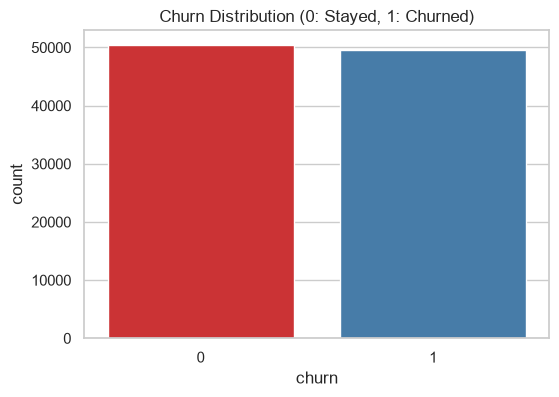

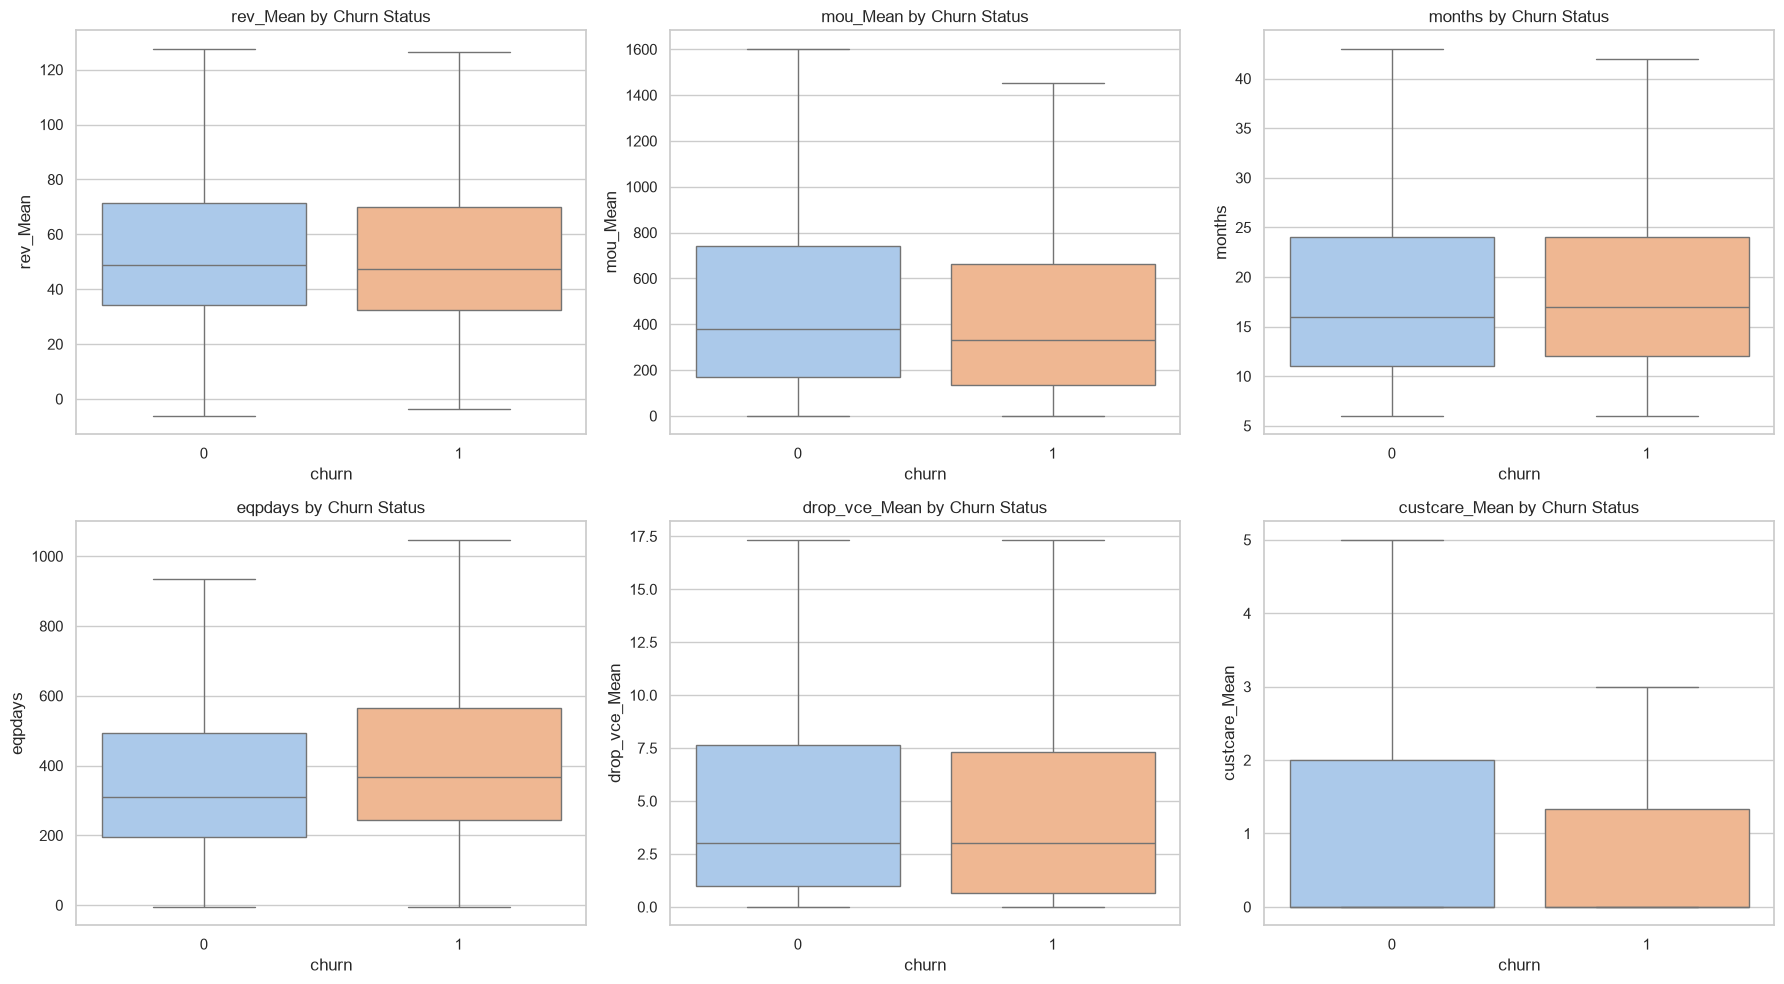

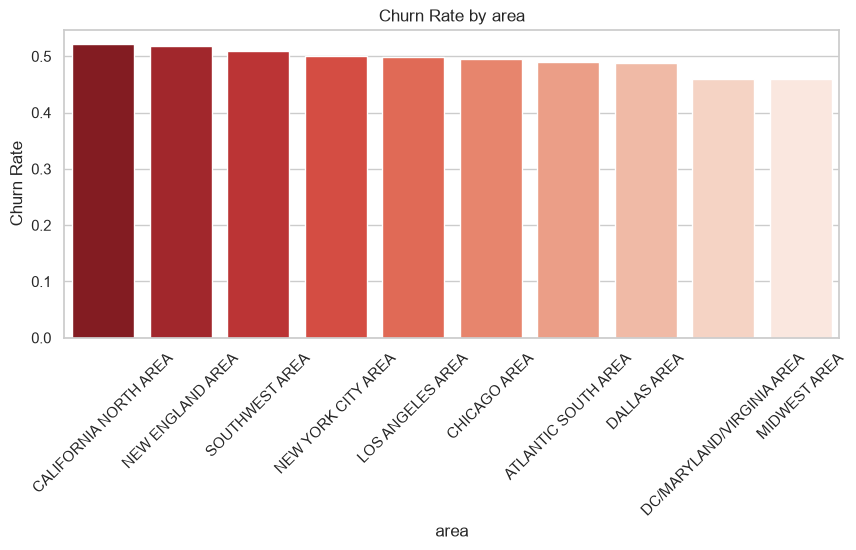

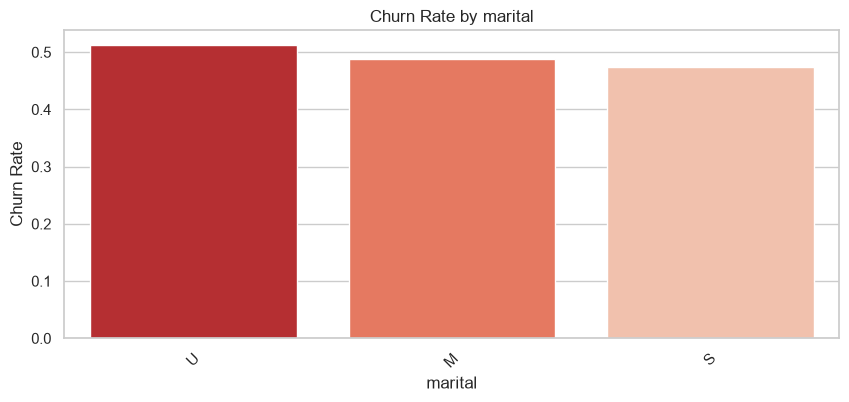

In [5]:
# 4. Churn Analysis
# Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='churn', data=df, palette='Set1')
plt.title('Churn Distribution (0: Stayed, 1: Churned)')
plt.show()

# Numerical vs Churn (Boxplots)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
cols_to_plot = ['rev_Mean', 'mou_Mean', 'months', 'eqpdays', 'drop_vce_Mean', 'custcare_Mean']
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    sns.boxplot(x='churn', y=col, data=df, ax=axes[i], palette='pastel', showfliers=False)
    axes[i].set_title(f'{col} by Churn Status')
plt.tight_layout()
plt.show()

# Categorical vs Churn (Churn Rate)
def plot_churn_rate(col, top_n=5):
    top_cats = df[col].value_counts().nlargest(top_n).index
    subset = df[df[col].isin(top_cats)]
    churn_rate = subset.groupby(col)['churn'].mean().sort_values(ascending=False)
    
    plt.figure(figsize=(10, 4))
    sns.barplot(x=churn_rate.index, y=churn_rate.values, palette='Reds_r')
    plt.title(f'Churn Rate by {col}')
    plt.ylabel('Churn Rate')
    plt.xticks(rotation=45)
    plt.show()

plot_churn_rate('area', top_n=10)
plot_churn_rate('marital', top_n=3)

**Target Distribution:** Based on the test data facts, churn is very evenly distributed (almost 50:50). This is rare in the real world (where churn is typically only 5-20%), but it facilitates the use of the Accuracy metric in the ML stage.

**Numeric vs. Churn:**

*   **`eqpdays`:** If the boxplot for `churn=1` shows a higher median, it means customers with older devices are more prone to churn. (**Implication:** Offer device upgrade programs).
*   **`rev_Mean` & `mou_Mean`:** If churned customers have lower values, it means low-value customers are easier to lose. (**Implication:** Focusing retention efforts on this segment may be less financially beneficial compared to retaining high-value users).
*   **`drop_vce_Mean` (dropped calls):** If the value is higher for `churn=1`, this proves that poor network quality triggers churn.

**Categorical vs. Churn:** Certain areas may have significantly higher churn rates. (**Implication:** Investigate network infrastructure or local competitors in those areas).

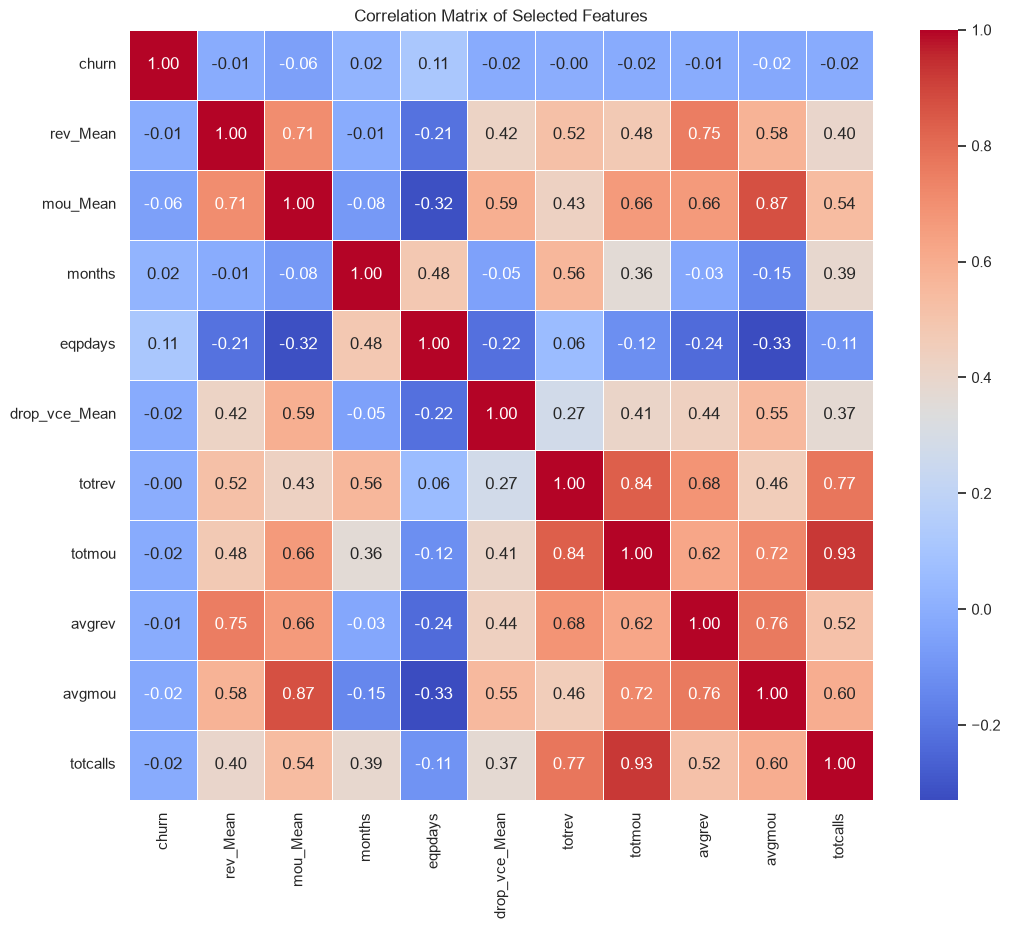


Features with >0.95 correlation to another feature: 15
['ovrrev_Mean', 'vceovr_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'mou_opkd_Mean', 'attempt_Mean', 'complete_Mean', 'adjrev', 'adjmou', 'adjqty', 'avg3mou', 'avg6mou', 'avg6qty']


In [6]:
# 5. Feature Relationships & Leakage Detection
# Correlation Matrix for Numerical Features
corr_cols = ['churn', 'rev_Mean', 'mou_Mean', 'months', 'eqpdays', 'drop_vce_Mean', 
             'totrev', 'totmou', 'avgrev', 'avgmou', 'totcalls']
plt.figure(figsize=(12, 10))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Selected Features')
plt.show()

# High Correlation Check (Automated)
corr_matrix = df.select_dtypes(include=[np.number]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
print(f"\nFeatures with >0.95 correlation to another feature: {len(to_drop)}")
print(to_drop[:20]) # Print top 20

**Multicollinearity:** Features such as `totrev`, `avgrev`, and `rev_Mean` will have very high correlation (>0.95) because they measure the same thing (revenue). The same applies to `totmou`, `avgmou`, and `mou_Mean`.

**Implication:** For tree-based models (XGBoost), multicollinearity does not significantly damage prediction accuracy, but it complicates the interpretation of feature importance. We may need to select a single representative feature (e.g., only `rev_Mean`) or combine them.

**Leakage:** We must ensure there are no features that directly reveal the churn status (for example, a "cancellation date" or "reason for leaving" feature). From the list of columns provided, there is no clear indication of leakage, but we must be cautious with `change_` (change) columns, as they might contain post-churn information if not defined correctly.

**Business Hypotheses to Test in the ML Model**

1.  **Hypothesis 1 (Equipment Lifecycle):** Customers with `eqpdays` (device age) above the 75th percentile have a significantly higher probability of churn. The ML model can predict the optimal device age threshold for offering upgrade subsidies.
2.  **Hypothesis 2 (Service Quality):** An increase in `drop_vce_Mean` (dropped calls) and `custcare_Mean` (calls to customer service) is positively correlated with churn. The model can identify whether network issues or customer service issues are the more dominant driver of churn.
3.  **Hypothesis 3 (Revenue Compression):** Customers with negative `change_rev` (revenue change/experiencing a bill decrease) have a higher risk of churn, as they may be downgrading their plans before completely leaving.
4.  **Hypothesis 4 (Geographic Segmentation):** Certain areas (identifiable from the `area` column) have statistically significantly higher churn rates, potentially due to local competitor penetration or poor network quality in those regions.